# Issue #203 — causal tensor and settlement-label contract

This bounded notebook verifies the immutable package, inspects coverage and held-out identity evidence, and never imports or opens the settlement-label namespace. Core logic remains in `unified_tensor`.

In [1]:
from pathlib import Path
import random
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src'))
random.seed(203)
np.random.seed(203)
PACKAGE = ROOT / 'results/bj203_causal_tensor_v1'
from unified_tensor.inference import load_issue_tensors
assert 'unified_tensor.settlement_labels' not in sys.modules

## Immutable package receipt

In [2]:
all_tensors = load_issue_tensors(PACKAGE)
receipt = {
    'contract_version': 'bj203-causal-tensor-v1',
    'issues': len(all_tensors),
    'matches': sum(len(tensor.match_ids) for tensor in all_tensors),
    'heldout_issues': sum(tensor.split == 'heldout' for tensor in all_tensors),
    'status': 'INFERENCE_PASS',
}
assert receipt['status'] == 'INFERENCE_PASS'
assert receipt['issues'] == 344 and receipt['matches'] == 102_245
assert receipt['heldout_issues'] == 2
display(pd.Series(receipt, name='value').to_frame())

,value
contract_version,bj203-causal-tensor-v1
issues,344
matches,102245
heldout_issues,2
status,INFERENCE_PASS


## Population and causal audit tables

These frozen tables expose the full year, league and native-line denominator plus every timing rule. Large league tables are summarized here and remain fully available in the package.

In [3]:
year_distribution = pd.read_csv(PACKAGE / 'audit/year_distribution.csv')
league_distribution = pd.read_csv(PACKAGE / 'audit/league_distribution.csv')
line_distribution = pd.read_csv(PACKAGE / 'audit/line_distribution.csv')
leakage_audit = pd.read_csv(PACKAGE / 'audit/leakage_audit.csv')
assert int(leakage_audit['unmasked_after_cutoff_cells'].sum()) == 0
assert set(leakage_audit['cutoff_check']) == {'PASS'}
display(year_distribution)
display(line_distribution)
display(league_distribution.groupby('split', sort=True)['match_rows'].agg(['sum', 'count']))
display(leakage_audit)

,split,year,match_rows
0,development,2019,17694
1,development,2020,12033
2,development,2021,18881
3,development,2022,16787
4,development,2023,15759
5,development,2024,16236
6,development,2025,3831
7,heldout,2025,1024


,split,native_line,match_rows
0,development,-2.0,1
1,development,-1.0,6
2,development,0.0,10
3,development,1.0,3
4,development,-0.5,1
5,development,-1.0,24324
6,development,-2.0,4828
7,development,-3.0,350
8,development,0.0,60631
9,development,1.0,9269


,sum,count
split,,
development,101221,184
heldout,1024,69


,feature,source,timing_rule,admissible_use,forbidden_name_check,source_after_cutoff_cells,unmasked_after_cutoff_cells,cutoff_check
0,outcome_code_numeric,canonical outcome axis,immutable identity known before the issue cutoff,inference,PASS,0,0,PASS
1,calibrated_market_probability,#190 calibrated match-safe 1h market estimator,1h snapshot cutoff (kickoff_ts_utc - 1h) is at...,inference,PASS,303744,0,PASS
2,devig_euro_probability,1h EURO consensus reciprocal odds normalized w...,1h snapshot cutoff (kickoff_ts_utc - 1h) is at...,inference,PASS,303744,0,PASS
3,euro_1h_odds,1h EURO consensus,1h snapshot cutoff (kickoff_ts_utc - 1h) is at...,inference,PASS,303744,0,PASS
4,fundamental_probability,#190 independent T1 score-distribution estimator,source observation is available at or before f...,inference,PASS,0,0,PASS
5,probability_residual,#190 calibrated probability minus its frozen t...,1h snapshot cutoff (kickoff_ts_utc - 1h) is at...,inference,PASS,303744,0,PASS
6,probability_residual_z,#190 calibrated residual standardized by froze...,1h snapshot cutoff (kickoff_ts_utc - 1h) is at...,inference,PASS,303744,0,PASS
7,predicted_final_sp,#90 chronological deployed 10h SP predictor,10h predictor input cutoff (kickoff_ts_utc - 1...,inference,PASS,282822,0,PASS
8,bj_sp_snapshot,timestamped pre-event Beijing SP snapshot,source observation is available at or before f...,inference,PASS,0,0,PASS
9,bj_sp_snapshot_age_minutes,cutoff minus timestamped Beijing SP observation,source observation is available at or before f...,inference,PASS,0,0,PASS


## Coverage and missingness

The zero-coverage BJ snapshot rows are intentional: no historical timestamp proves those SP values were observable by the issue cutoff.

,split,total_cells,feature_count,fully_covered_features,fully_masked_features,mean_feature_coverage
0,development,303663,24,4,2,0.547433
1,heldout,3072,24,13,2,0.545247


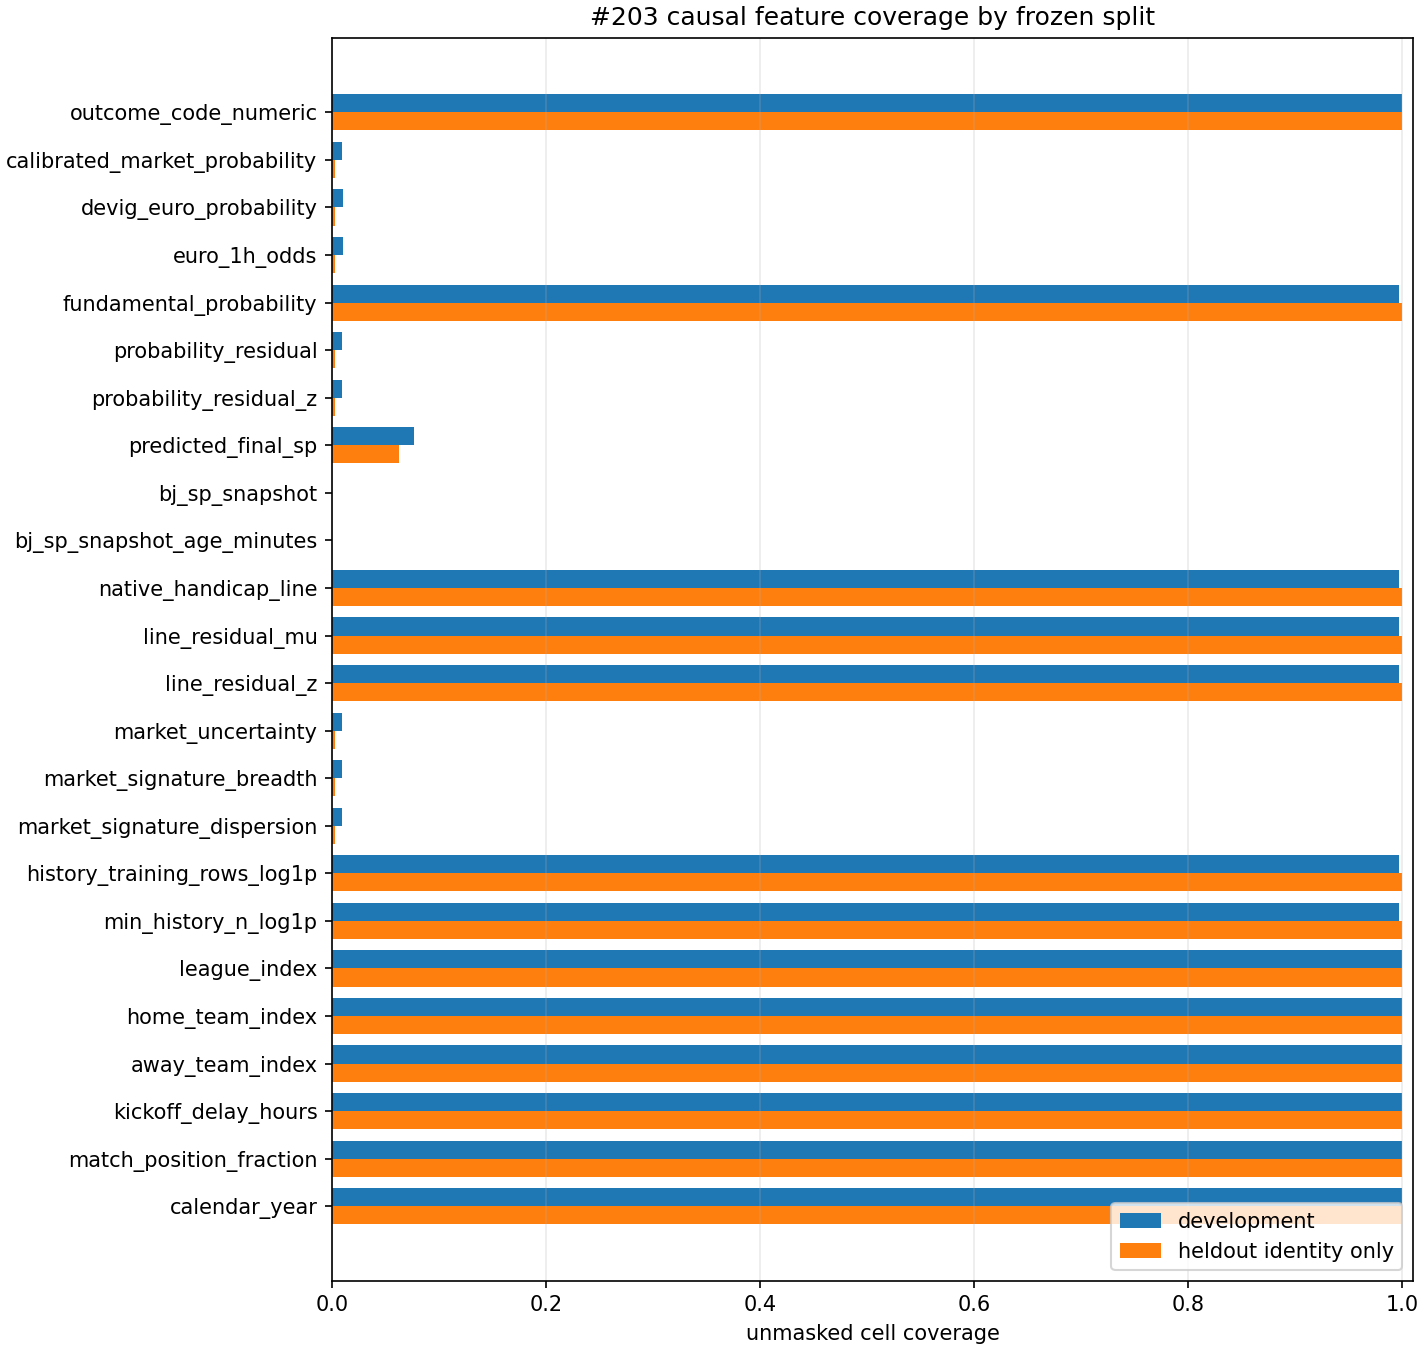

In [4]:
coverage_summary = pd.read_csv(PACKAGE / 'analysis/coverage_summary.csv')
display(coverage_summary)
display(Image(filename=str(PACKAGE / 'analysis/feature_coverage.png')))

## Held-out boundary and inference-only load

In [5]:
heldout_registry = pd.read_csv(PACKAGE / 'audit/heldout_registry.csv', dtype=str)
heldout_tensors = tuple(tensor for tensor in all_tensors if tensor.split == 'heldout')
assert tuple(heldout_registry['issue']) == ('25041', '25042')
assert len(heldout_tensors) == 2
assert set(heldout_registry['label_status']) == {'ABSENT_BY_CONTRACT'}
assert not list((PACKAGE / 'labels').glob('*heldout*'))
display(heldout_registry)

,issue,issue_instance,feature_cutoff_ts_utc,match_count,cell_count,ordered_identity_sha256,label_status
0,25041,25041@CANONICAL_2025,2025-03-31T14:30:00Z,548,1644,814e2674330e7dd51e51bf2d4a1a28199878e487e8725f...,ABSENT_BY_CONTRACT
1,25042,25042@CANONICAL_2025,2025-04-08T16:00:00Z,476,1428,7760c4e96a5e8bc2b1ebed53487e6d55d130c5d3883325...,ABSENT_BY_CONTRACT


## Decision and challenger rebuttal

The handoff is suitable for downstream probability/SP work only through the inference loader. The issue-level cutoff leaves roughly 1% development coverage for 1h market cells and 8% for 10h predicted-SP cells; #204 must honor those masks, while any rolling-time reinterpretation requires a new PI-approved contract and package version. A challenger might claim the held-out embargo is cosmetic because labels exist elsewhere in the runtime database; that does not defeat this package boundary: the held-out rows are physically absent from the label payload, the default loader never opens `labels/`, and the negative contract tests reject outcome/final-SP fields moved into inference. This artifact does not claim universal feature coverage, model lift, ROI, or betting authorization.